# 04 · Resume eight-shard embeddings and build retrieval indexes
Generate only uncommitted batches, then prepare matching semantic and lexical indexes.

## Portable project folder and database settings
Keep notebooks 01–05 together in the project folder. All data, models and results use paths relative to that folder through `pathlib`, on macOS, Windows or Linux. The code searches the kernel working directory and its parents for notebook 01. Jupyter does not reliably expose the open notebook's file path; if its working directory is elsewhere, set `RAG_PROJECT_DIR` to the project folder before running configuration. A relative override is resolved from the kernel working directory.

Optional override in a cell before configuration:
```python
import os
os.environ['RAG_PROJECT_DIR'] = 'path/to/your/project'  # Relative, or your native absolute path.
```

Database settings in 03–05 follow this precedence: `RAG_PG_DSN` / `RAG_PG_SCHEMA` environment overrides, then `data/rag_setup_connection.json` saved by 03, then the local defaults. On a new machine, run 03 to prepare the connection before 04/05. Supply the PostgreSQL role in the DSN when it differs from your operating-system username. Credentials remain in your environment or PostgreSQL password file; do not put passwords in notebook cells. A saved endpoint is machine-specific: override it when moving to another server. Notebook 03 saves the effective endpoint without its password.

The scope is intentional: notebook 01 downloads **all 41 English shards**, and notebook 04 embeds only **00000–00007** to limit computation. No download or embedding scope is changed by the portable paths.


## Run order and scope
Run **01 → 02 → 03 → 04 → 05_offline_wikipedia_hybrid_rag.ipynb** from the project directory.
Notebook 01 downloads English Wikipedia; notebook 02 downloads the answer generator. These two new notebooks prepare retrieval storage and embeddings.

“Shards 1–8” means the **first eight files, numbered 00000–00007**, not upstream files 00001–00008. These contain 1,250,310 articles in the pinned snapshot. The full English snapshot is approximately 11.63 GB of compressed Parquet across 41 files; this subset uses about 2.48 GB of source files. Database tables, model weights and indexes require additional disk space.

Use Python 3.11 or 3.12 in a dedicated environment. Existing PostgreSQL must have the pgvector extension installed on the server and a role allowed to create the database/schema/extension. Alternatively, install and start Docker Desktop/Engine and enable the optional container switch in notebook 03. Docker itself is an operating-system prerequisite. No service is restarted or upgraded by these notebooks.

First downloads require internet; model inference and retrieval are local after preparation. A populated database and a corpus-specific BM25 index are **built or restored**, not downloadable pretrained models. This is a reproducible local project pipeline; production deployments also need access control, backups, monitoring and workload-specific evaluation.

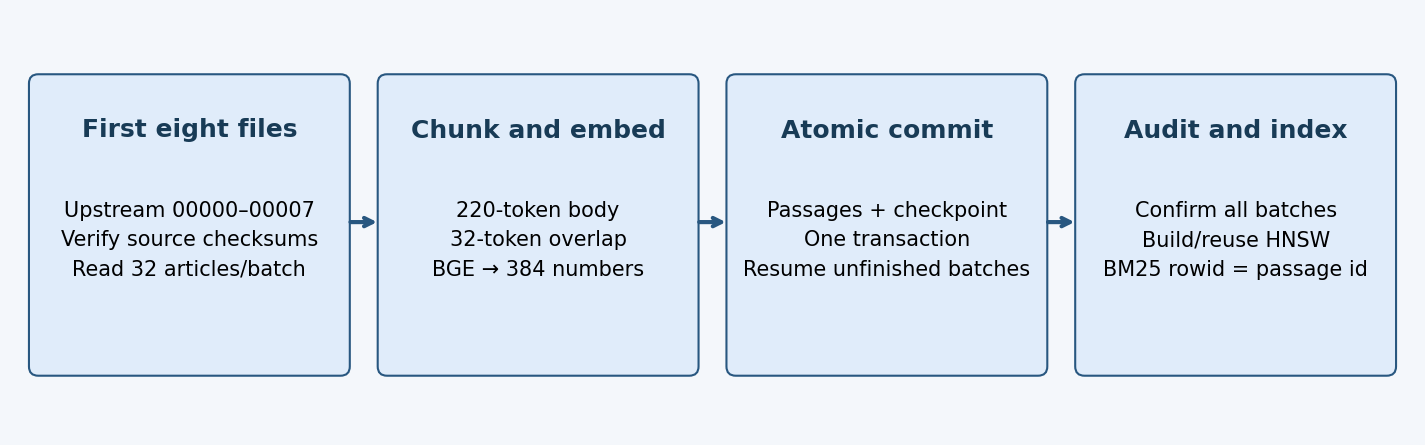

In [1]:
# Install missing packages only, in this notebook kernel. Internet required on first setup.
import importlib.util, subprocess, sys
packages = {'pyarrow':'pyarrow>=14', 'numpy':'numpy', 'psycopg':'psycopg[binary]>=3.2',
            'pgvector':'pgvector>=0.3', 'huggingface_hub':'huggingface-hub',
            'sentence_transformers':'sentence-transformers>=3', 'torch':'torch',
            'transformers':'transformers', 'sentencepiece':'sentencepiece'}
missing=[package for module,package in packages.items() if importlib.util.find_spec(module) is None]
if missing: subprocess.check_call([sys.executable,'-m','pip','install',*missing])
print('Dependencies present. If pip changed an already loaded dependency, restart the kernel.')

Dependencies present. If pip changed an already loaded dependency, restart the kernel.


In [2]:
from pathlib import Path
import os, json
# Paths are relative to the project folder, using native macOS/Windows separators.
def resolve_project_root():
    override = os.environ.get('RAG_PROJECT_DIR')
    if override:
        folder = Path(override).expanduser().resolve()
        if not folder.is_dir():
            raise FileNotFoundError('RAG_PROJECT_DIR must point to an existing project folder.')
        return folder
    current = Path.cwd().resolve()
    for folder in (current, *current.parents):
        if (folder/'01_download_english_wikipedia_dataset.ipynb').is_file():
            return folder
    raise RuntimeError('Open Jupyter from the folder containing notebooks 01–05, or set RAG_PROJECT_DIR to that folder.')

ROOT = resolve_project_root()
ROOT.joinpath('data').mkdir(parents=True, exist_ok=True)
connection_file = ROOT/'data/rag_setup_connection.json'
saved = json.loads(connection_file.read_text(encoding='utf-8')) if connection_file.exists() else {}
DSN = os.environ.get('RAG_PG_DSN') or saved.get('dsn') or 'host=localhost dbname=rag_vectors'
SCHEMA = os.environ.get('RAG_PG_SCHEMA') or saved.get('schema') or 'rag_wiki_bge_full_v1'
print('Project folder:', ROOT)  # Credentials are never printed.


Project folder: /Users/amolsingh/Documents/code/IITB-DL


## Why this sequence?
1. Validate source checksums and model files before changing the collection.
2. Keep existing chunk rules: up to 220 body tokens, 28 title tokens, 32-token overlap, sentence boundaries where possible, maximum 256 total input tokens.
3. Stream 32 articles per source batch; encode chunks using CPU, CUDA or Apple MPS. The source batch size stays fixed to preserve checkpoint identities.
4. Commit passage rows and their checkpoint in one PostgreSQL transaction. Interrupted uncommitted work rolls back; rerunning skips committed batches.
5. Audit every expected batch and passage count before marking the eight-shard subset ready.
6. Build missing HNSW and aligned BM25 indexes; validate and reuse existing ones.

The dataset is [wikimedia/wikipedia](https://huggingface.co/datasets/wikimedia/wikipedia), English `20231101.en`, pinned revision `b04c8d1ceb2f5cd4588862100d08de323dccfbaa`. This notebook expects notebook 01's downloaded files; it does not download all 41 again. No Flan-T5 model is needed while embedding.

In [3]:
MODEL_SPECS = [{'repo_id': 'BAAI/bge-small-en-v1.5', 'repo_type': 'model', 'revision': '5c38ec7c405ec4b44b94cc5a9bb96e735b38267a', 'folder': 'bge-small-en-v1.5', 'files': [{'path': '1_Pooling/config.json', 'size': 190, 'git_sha1': '1da070f0993788c8851a652170ff013aa54dd519'}, {'path': 'README.md', 'size': 94783, 'git_sha1': '8b8567d75ffa619486d9590cb0eb76d66ad46c49'}, {'path': 'config.json', 'size': 743, 'git_sha1': '3992bf890728a92476c700e6e657fd696eb94160'}, {'path': 'config_sentence_transformers.json', 'size': 124, 'git_sha1': 'dcb0c0d97d09b930d13600b1a773ddb27e441aab'}, {'path': 'model.safetensors', 'size': 133466304, 'sha256': '3c9f31665447c8911517620762200d2245a2518d6e7208acc78cd9db317e21ad'}, {'path': 'modules.json', 'size': 349, 'git_sha1': '952a9b81c0bfd99800fabf352f69c7ccd46c5e43'}, {'path': 'sentence_bert_config.json', 'size': 52, 'git_sha1': 'ea85692bff64b0d1917833c31ddbca8ab10f5455'}, {'path': 'special_tokens_map.json', 'size': 125, 'git_sha1': 'a8b3208c2884c4efb86e49300fdd3dc877220cdf'}, {'path': 'tokenizer.json', 'size': 711396, 'git_sha1': '688882a79f44442ddc1f60d70334a7ff5df0fb47'}, {'path': 'tokenizer_config.json', 'size': 366, 'git_sha1': '37fca74771bc76a8e01178ce3a6055a0995f8093'}, {'path': 'vocab.txt', 'size': 231508, 'git_sha1': 'fb140275c155a9c7c5a3b3e0e77a9e839594a938'}]}, {'repo_id': 'cross-encoder/ms-marco-MiniLM-L6-v2', 'repo_type': 'model', 'revision': '233902d25c440f23af6f7d6e94d2946bac0bee0a', 'folder': 'ms-marco-MiniLM-L6-v2', 'files': [{'path': 'README.md', 'size': 3673, 'git_sha1': '4c0467b102d751d799638ad2bc0cdf6de56e9745'}, {'path': 'config.json', 'size': 794, 'git_sha1': '88bc4f74b33a2073abc9a66cb532b889448ac3ed'}, {'path': 'model.safetensors', 'size': 90870598, 'sha256': '821d1aa69520101d6e0737f78a042ae25b19e5cb9160701909d10434f4aeb0ae'}, {'path': 'special_tokens_map.json', 'size': 132, 'git_sha1': '7520992f25914d962f0e2fd0e0566fc33d19ec59'}, {'path': 'tokenizer.json', 'size': 711396, 'git_sha1': '688882a79f44442ddc1f60d70334a7ff5df0fb47'}, {'path': 'tokenizer_config.json', 'size': 1330, 'git_sha1': 'a2435fedfac32b9ad70f052d4f84007730cd3109'}, {'path': 'vocab.txt', 'size': 231508, 'git_sha1': 'fb140275c155a9c7c5a3b3e0e77a9e839594a938'}]}]
SHARD_FILES = [{'path': '20231101.en/train-00000-of-00041.parquet', 'size': 420296449, 'sha256': '382e7f6f09e488b24793a7f7cfc659879d5a22da2cf2efec6491665f0c019677'}, {'path': '20231101.en/train-00001-of-00041.parquet', 'size': 351448367, 'sha256': '6cd57a5825312ca966313d4a1b614690b5c4fb53cee9b124bc0e999977eb36cf'}, {'path': '20231101.en/train-00002-of-00041.parquet', 'size': 329024669, 'sha256': 'b18674f163d4f106e43396fd58412a79b80a418c72bb728c20af439e7ca4d5b7'}, {'path': '20231101.en/train-00003-of-00041.parquet', 'size': 330779424, 'sha256': '0b8a6f452f5ef59d0986a067f70110feb16d7c1d281ba2db0b3df32933618fcc'}, {'path': '20231101.en/train-00004-of-00041.parquet', 'size': 306945391, 'sha256': '1424300f113c13ee022b7929185fa4f7e20c6195ba563d728e8a3dc47c8e9aba'}, {'path': '20231101.en/train-00005-of-00041.parquet', 'size': 243974056, 'sha256': '220d31bb222ba2d449c845733622a6a2b7a89db3e28b24bfcb3a9bb3e52c6c8d'}, {'path': '20231101.en/train-00006-of-00041.parquet', 'size': 266288728, 'sha256': 'b8becbe9989a2c63f129a707a4674a84fb093c163673b1f4ce97afbf5306f04c'}, {'path': '20231101.en/train-00007-of-00041.parquet', 'size': 228195804, 'sha256': 'adebba8b075444923ba42ed6214fe205efc756c773f440d98cbdd88a33597c2c'}]
BASE_CONFIG = {'dim': 384, 'chunker': {'version': 1, 'body_tokens': 220, 'title_tokens': 28, 'overlap_tokens': 32}, 'storage': 'halfvec', 'model_id': 'BAAI/bge-small-en-v1.5', 'normalized': True, 'model_revision': '5c38ec7c405ec4b44b94cc5a9bb96e735b38267a', 'source_batch_size': 32}

In [4]:
# Shared setup definitions embedded in the preparation notebooks.
from pathlib import Path
from contextlib import contextmanager
import os,sys,json,re,time,hashlib,shutil,subprocess,importlib.util,threading,socket,getpass
import pyarrow.parquet as pq  # Import before torch to avoid conflicting OpenMP initialization.
import numpy as np
import psycopg
from psycopg import sql
from psycopg.rows import dict_row
from psycopg.conninfo import conninfo_to_dict,make_conninfo
from pgvector.psycopg import register_vector
from pgvector import HalfVector

def safe_schema(name):
    if not re.fullmatch(r'rag_[a-z0-9_]{1,50}',name):raise ValueError('Use a schema beginning rag_ with lowercase letters/digits/underscores.')
    return name

def connect(dsn,vector=True):
    db=psycopg.connect(dsn,autocommit=True,row_factory=dict_row,connect_timeout=5)
    if vector:register_vector(db)
    return db

@contextmanager
def writer_lock(db,schema):
    locked=db.execute('SELECT pg_try_advisory_lock(hashtext(%s)) AS ok',(schema,)).fetchone()['ok']
    if not locked:raise RuntimeError('Another ingestion/index writer is active for this schema; retry after it finishes.')
    try:yield
    finally:db.execute('SELECT pg_advisory_unlock(hashtext(%s))',(schema,))

def get_meta(db,schema):
    return {r['key']:r['value'] for r in db.execute(f'SELECT * FROM {safe_schema(schema)}.metadata')}

def put_meta(db,schema,key,value):
    db.execute(f'INSERT INTO {safe_schema(schema)}.metadata VALUES (%s,%s::jsonb) ON CONFLICT(key) DO UPDATE SET value=excluded.value',(key,json.dumps(value)))

def file_hash(path,algorithm='sha256',git_header=False):
    digest=hashlib.new(algorithm)
    if git_header:digest.update(f'blob {path.stat().st_size}\0'.encode())
    with path.open('rb') as stream:
        for block in iter(lambda:stream.read(8*1024*1024),b''):digest.update(block)
    return digest.hexdigest()

def asset_valid(path,entry,verify=True):
    if not path.is_file() or path.stat().st_size!=entry['size']:return False
    if not verify:return True
    return file_hash(path) == entry['sha256'] if 'sha256' in entry else file_hash(path,'sha1',True)==entry['git_sha1']

def ensure_models(root,specs,allow_download=True,verify=True):
    for spec in specs:
        folder=Path(root)/'models'/spec['folder']
        invalid=[e for e in spec['files'] if not asset_valid(folder/e['path'],e,verify)]
        if not invalid:print(spec['repo_id'],': verified; download skipped.');continue
        if not allow_download:raise FileNotFoundError(f"Missing/invalid model files: {spec['repo_id']}")
        folder.mkdir(parents=True,exist_ok=True)
        if shutil.disk_usage(folder).free<sum(e['size'] for e in invalid)+256*1024**2:raise OSError('Insufficient free space for model download.')
        # Fresh subprocess ignores offline flags inherited from an earlier RAG session.
        payload=dict(repo_id=spec['repo_id'],revision=spec['revision'],local_dir=str(folder.resolve()),
                     missing=[e['path'] for e in invalid if not (folder/e['path']).exists()],
                     repair=[e['path'] for e in invalid if (folder/e['path']).exists()])
        program="""import json,sys
from huggingface_hub import snapshot_download
p=json.load(sys.stdin)
for key,force in [('missing',False),('repair',True)]:
 if p[key]:snapshot_download(p['repo_id'],revision=p['revision'],local_dir=p['local_dir'],allow_patterns=p[key],force_download=force,max_workers=4)
"""
        env=os.environ.copy()
        for key in ['HF_HUB_OFFLINE','TRANSFORMERS_OFFLINE','HF_DATASETS_OFFLINE']:env[key]='0'
        subprocess.run([sys.executable,'-u','-c',program],input=json.dumps(payload),text=True,env=env,check=True)
        if any(not asset_valid(folder/e['path'],e,verify) for e in spec['files']):raise RuntimeError('Model download did not validate; rerun to resume.')
        print(spec['repo_id'],': download complete.')

DDL_TEMPLATE='''CREATE SCHEMA IF NOT EXISTS {schema};
CREATE TABLE IF NOT EXISTS {schema}.metadata (
    key text PRIMARY KEY, value jsonb NOT NULL
);
CREATE TABLE IF NOT EXISTS {schema}.chunks (
    id bigint GENERATED ALWAYS AS IDENTITY PRIMARY KEY,
    chunk_id text UNIQUE NOT NULL,
    article_id text NOT NULL, title text NOT NULL, url text NOT NULL,
    body text NOT NULL, char_start integer NOT NULL, char_end integer NOT NULL,
    embedding halfvec(384) NOT NULL
);
CREATE TABLE IF NOT EXISTS {schema}.checkpoints (
    unit text PRIMARY KEY, articles bigint, chunks bigint, seconds double precision
);'''

def provision_database(dsn,*,use_docker=False,docker_name='wiki-rag-postgres',docker_image='pgvector/pgvector:pg16'):
    params=conninfo_to_dict(dsn);target=params.get('dbname','rag_vectors');db=None
    try:db=connect(dsn,vector=False)
    except psycopg.errors.InvalidCatalogName:
        admin=connect(make_conninfo(dsn,dbname='postgres'),vector=False)
        try:
            if not admin.execute('SELECT 1 FROM pg_database WHERE datname=%s',(target,)).fetchone():
                admin.execute(sql.SQL('CREATE DATABASE {}').format(sql.Identifier(target)))
        finally:admin.close()
        db=connect(dsn,vector=False)
    except psycopg.OperationalError:
        host=params.get('host','localhost');port=int(params.get('port',5432))
        if not use_docker or host not in {'localhost','127.0.0.1'}:raise
        # Never launch a competing server when the target port already has a service.
        try:
            sock=socket.create_connection((host,port),timeout=2);sock.close();occupied=True
        except OSError:occupied=False
        if occupied:raise RuntimeError('PostgreSQL port is occupied but login failed. Fix credentials; no second server was started.')
        if not shutil.which('docker'):raise RuntimeError('Install and start Docker Desktop/Engine, or configure an existing PostgreSQL server with pgvector; then rerun.')
        subprocess.run(['docker','info'],check=True,stdout=subprocess.DEVNULL)
        if not re.fullmatch(r'[a-zA-Z0-9_-]+',docker_name):raise ValueError('Invalid container name.')
        existing=subprocess.run(['docker','inspect',docker_name],capture_output=True,text=True)
        password=params.get('password') or os.environ.get('PGPASSWORD') or getpass.getpass('PostgreSQL password for the local RAG container: ')
        if not password:raise ValueError('A non-empty PostgreSQL password is required.')
        if existing.returncode==0:
            info=json.loads(existing.stdout)[0]
            if info.get('Config',{}).get('Labels',{}).get('rag.setup')!='wikipedia-eight-shards':raise RuntimeError('Container name belongs to another service. Choose a different name.')
            ports=info.get('HostConfig',{}).get('PortBindings',{}).get('5432/tcp',[])
            if not any(p.get('HostPort')==str(port) and p.get('HostIp')=='127.0.0.1' for p in ports):raise RuntimeError('Existing container port does not match the requested endpoint.')
            subprocess.run(['docker','start',docker_name],check=True,stdout=subprocess.DEVNULL)
        else:
            # Password supplied via child environment, never embedded in command arguments/output.
            env=os.environ.copy();env['POSTGRES_PASSWORD']=password
            subprocess.run(['docker','run','-d','--name',docker_name,'--label','rag.setup=wikipedia-eight-shards',
                '--restart','unless-stopped','-p',f'127.0.0.1:{port}:5432','-e','POSTGRES_PASSWORD','-e','POSTGRES_DB='+target,
                '-v',docker_name+'-data:/var/lib/postgresql/data',docker_image],env=env,check=True,stdout=subprocess.DEVNULL)
        os.environ['PGPASSWORD']=password
        dsn=make_conninfo(host='127.0.0.1',port=port,user='postgres',dbname=target)
        for attempt in range(30):
            try:db=connect(dsn,vector=False);break
            except psycopg.OperationalError:time.sleep(2)
        if db is None:raise RuntimeError('Container started but PostgreSQL is not ready; inspect Docker logs and retry.')
    try:
        db.execute('CREATE EXTENSION IF NOT EXISTS vector')
        version=db.execute("SELECT extversion FROM pg_extension WHERE extname='vector'").fetchone()['extversion']
        if tuple(int(x) for x in version.split('.')[:2])<(0,7):raise RuntimeError('halfvec requires pgvector 0.7 or newer; upgrade separately.')
        print('PostgreSQL connected; pgvector',version)
    finally:db.close()
    return dsn

def ensure_tables(db,schema):
    schema=safe_schema(schema)
    with writer_lock(db,schema),db.transaction():
        for statement in DDL_TEMPLATE.format(schema=schema).split(';'):
            if statement.strip():db.execute(statement)
        required={'chunks':{'id':'bigint','chunk_id':'text','article_id':'text','title':'text','url':'text','body':'text','char_start':'integer','char_end':'integer','embedding':'halfvec(384)'},
                  'metadata':{'key':'text','value':'jsonb'},'checkpoints':{'unit':'text','articles':'bigint','chunks':'bigint','seconds':'double precision'}}
        for table,expected in required.items():
            rows=db.execute('SELECT a.attname,format_type(a.atttypid,a.atttypmod) AS type FROM pg_attribute a WHERE a.attrelid=to_regclass(%s) AND a.attnum>0 AND NOT a.attisdropped',(schema+'.'+table,)).fetchall()
            if {r['attname']:r['type'] for r in rows}!=expected:raise RuntimeError('Existing '+table+' table is incompatible; use a separate schema, do not overwrite it.')
        constraints=db.execute("SELECT pg_get_constraintdef(oid) AS definition FROM pg_constraint WHERE conrelid=to_regclass(%s)",(schema+'.chunks',)).fetchall()
        defs={r['definition'] for r in constraints}
        if 'PRIMARY KEY (id)' not in defs or 'UNIQUE (chunk_id)' not in defs:raise RuntimeError('Missing passage identity constraints.')
    print('Schema and tables validated:',schema)

In [5]:
from sentence_transformers import SentenceTransformer
QUERY_PREFIX = "Represent this sentence for searching relevant passages: "
DIM = 384
import sqlite3,bisect,math

def source_manifest(snapshot,inventory):
    files=[]
    for entry in inventory:
        path=Path(snapshot)/entry['path']
        if not asset_valid(path,entry):raise RuntimeError(f'Missing/corrupt {path}; run notebook 01 first.')
        files.append(dict(name=path.name,size=entry['size'],sha256=entry['sha256'],articles=pq.ParquetFile(path).metadata.num_rows))
        print('Verified',path.name,files[-1]['articles'],'articles',flush=True)
    return dict(scope='eight_shard_subset',dataset='wikimedia/wikipedia',snapshot='20231101.en',revision='b04c8d1ceb2f5cd4588862100d08de323dccfbaa',files=files)

def validate_config(db,s,config):
    old=get_meta(db,s).get('config')
    if old:
        for key in ('dim','chunker','storage','model_id','normalized','model_revision','source_batch_size'):
            if old.get(key)!=config[key]:raise ValueError('Incompatible collection '+key+'; use a new schema.')
        for key in ('dataset','snapshot','revision'):
            if old['source'].get(key)!=config['source'][key]:raise ValueError('Source mismatch: '+key)
        previous={f['name']:f for f in old['source']['files']}
        for f in config['source']['files']:
            if f['name'] not in previous or any(previous[f['name']].get(k)!=f[k] for k in ('size','articles')):raise ValueError('Shard manifest mismatch')
        if 'sha256' in previous[f['name']] and previous[f['name']]['sha256']!=f.get('sha256'):raise ValueError('Shard checksum provenance mismatch')
        return old  # Preserve legacy metadata exactly: the BM25 fingerprint depends on it.
    if db.execute(f'SELECT EXISTS(SELECT 1 FROM {s}.chunks) AS yes').fetchone()['yes']:raise ValueError('Rows without provenance cannot be resumed safely.')
    put_meta(db,s,'config',config)
    return config

def coverage(db,s,source):
    expected={f"{f['name']}:{i}":min(32,f['articles']-i*32) for f in source['files'] for i in range(math.ceil(f['articles']/32))}
    rows=db.execute(f'SELECT * FROM {s}.checkpoints').fetchall();done={r['unit']:r for r in rows}
    for unit,r in done.items():
        if unit not in expected or r['articles']!=expected[unit] or r['chunks'] is None or r['chunks']<0:raise ValueError('Invalid/out-of-scope checkpoint: '+unit)
    actual=db.execute(f'SELECT count(*) AS n FROM {s}.chunks').fetchone()['n']
    if actual!=sum(r['chunks'] for r in rows):raise ValueError('Passage/checkpoint counts disagree; investigate before resuming.')
    return expected,done,actual

def ingest_missing(db,s,source,snapshot,embedder_factory,db_storage_path=None,min_free_gb=30):
    expected,done,count=coverage(db,s,source)
    if set(expected)==set(done):print('All eight shards already embedded; inference skipped.');return
    put_meta(db,s,'subset_ready',False)
    embedder=embedder_factory();started=time.monotonic();articles_done=sum(r['articles'] for r in done.values())
    for f in source['files']:
        units=[u for u in expected if u.startswith(f['name']+':')]
        if all(u in done for u in units):print('Skipping completed',f['name']);continue
        path=Path(snapshot)/source['snapshot']/f['name']
        for i,batch in enumerate(pq.ParquetFile(path).iter_batches(batch_size=32,columns=['id','title','url','text'],use_threads=False)):
            unit=f"{f['name']}:{i}"
            if unit in done:continue
            if db_storage_path and shutil.disk_usage(db_storage_path).free<min_free_gb*1e9:raise OSError('Low database disk space. Committed batches are safe; free space and rerun.')
            tick=time.monotonic();articles=batch.to_pylist();chunks=[p for a in articles for p in embedder.chunk(a)]
            vectors=embedder.encode([p['embed_text'] for p in chunks]) if chunks else []
            with db.transaction():
                with db.cursor().copy(f'COPY {s}.chunks (chunk_id,article_id,title,url,body,char_start,char_end,embedding) FROM STDIN') as writer:
                    for p,v in zip(chunks,vectors):writer.write_row((p['chunk_id'],p['article_id'],p['title'],p['url'],p['text'],p['char_start'],p['char_end'],HalfVector(v)))
                db.execute(f'INSERT INTO {s}.checkpoints VALUES (%s,%s,%s,%s)',(unit,len(articles),len(chunks),time.monotonic()-tick))
            articles_done+=len(articles);count+=len(chunks)
            if i%20==0 or i==len(units)-1:print(f'{unit}: {articles_done:,}/{sum(expected.values()):,} articles; {count:,} chunks; session {time.monotonic()-started:.0f}s',flush=True)
    expected,done,count=coverage(db,s,source)
    if set(expected)!=set(done):raise RuntimeError('Incomplete shard coverage')

def audit_subset(db,s,source):
    expected,done,count=coverage(db,s,source)
    if set(expected)!=set(done):raise RuntimeError('Finish embedding before building indexes.')
    audit=dict(scope='eight_shard_subset',chunks=count,shards=[f['name'] for f in source['files']],articles=sum(expected.values()),full_corpus_complete=False)
    put_meta(db,s,'subset_audit',audit)
    return audit

def ensure_indexes(db,s,dsn,maintenance_mb=512):
    definitions=[('chunks_half_hnsw','hnsw','embedding halfvec_cosine_ops',' WITH (m=16,ef_construction=128)'),('chunks_article_start_idx','btree','article_id, char_start','')]
    for name,method,expression,options in definitions:
        row=db.execute('''SELECT i.indisvalid,i.indisready,pg_get_indexdef(i.indexrelid) AS definition,c.reloptions
            FROM pg_index i JOIN pg_class c ON c.oid=i.indexrelid WHERE i.indexrelid=to_regclass(%s)''',(s+'.'+name,)).fetchone()
        if row:
            definition=row['definition']
            if not row['indisvalid'] or not row['indisready'] or f'ON {s}.chunks USING {method} ({expression})' not in definition or ' WHERE ' in definition:raise RuntimeError('Existing index is incompatible: '+name)
            if method=='hnsw' and not {'m=16','ef_construction=128'}.issubset(set(row['reloptions'] or [])):raise RuntimeError('HNSW build parameters differ; inspect before reuse.')
            print('Reusing valid index:',name);continue
        db.execute("SELECT set_config('maintenance_work_mem',%s,false)",(f'{int(maintenance_mb)}MB',))
        stop=threading.Event();pid=db.info.backend_pid
        def monitor():
            try:
                with connect(dsn,vector=False) as watcher:
                    while not stop.wait(15):
                        row=watcher.execute('SELECT phase,blocks_done,blocks_total,tuples_done,tuples_total FROM pg_stat_progress_create_index WHERE pid=%s',(pid,)).fetchone()
                        if row:print('Index progress:',row,flush=True)
            except Exception as exc:print('Progress monitor unavailable:',type(exc).__name__)
        worker=threading.Thread(target=monitor,daemon=True);worker.start()
        try:
            print('Building',name,'— this may take hours on a large collection.',flush=True)
            db.execute(f'CREATE INDEX {name} ON {s}.chunks USING {method} ({expression}){options}')
        finally:stop.set();worker.join(timeout=6)
        db.execute(f'ANALYZE {s}.chunks')
    put_meta(db,s,'index_half',True);put_meta(db,s,'subset_ready',True)

def ensure_bm25(pg,s,final,min_free_gb=10):
    final=Path(final).resolve();final.parent.mkdir(parents=True,exist_ok=True)
    meta=get_meta(pg,s);expected=meta['subset_audit']['chunks']
    fingerprint=dict(schema=s,audit=meta['subset_audit'],config=meta['config'],tokenizer='porter unicode61',version=1)
    def metadata(db):return {k:json.loads(v) for k,v in db.execute('SELECT key,value FROM metadata')}
    def put(db,k,v):db.execute('INSERT OR REPLACE INTO metadata VALUES (?,?)',(k,json.dumps(v)))
    if final.exists():
        with sqlite3.connect(final.as_uri()+'?mode=ro',uri=True) as db:
            m=metadata(db);n=db.execute('SELECT count(*) FROM search_docsize').fetchone()[0]
            if not m.get('complete') or m.get('fingerprint')!=fingerprint or m.get('documents')!=expected or n!=expected:raise RuntimeError('Existing BM25 is not aligned. Preserve it and select a new path or restore the matching DB.')
        print('BM25 already aligned:',f'{n:,}','passages; build skipped.');return
    temp=final.with_suffix('.building.sqlite');db=sqlite3.connect(temp)
    try:
        db.execute('PRAGMA journal_mode=WAL');db.execute('PRAGMA synchronous=FULL')
        db.execute('CREATE TABLE IF NOT EXISTS metadata(key TEXT PRIMARY KEY,value TEXT NOT NULL)')
        db.execute("CREATE VIRTUAL TABLE IF NOT EXISTS search USING fts5(title,body,content='',tokenize='porter unicode61')")
        m=metadata(db)
        if m and m.get('fingerprint')!=fingerprint:raise ValueError('BM25 staging file belongs to another collection.')
        last=m.get('last_id',0);count=m.get('documents',0)
        if db.execute('SELECT count(*) FROM search_docsize').fetchone()[0]!=count:raise ValueError('BM25 checkpoint count mismatch')
        put(db,'fingerprint',fingerprint);db.commit()
        while True:
            if shutil.disk_usage(temp.parent).free<min_free_gb*1e9:raise OSError('Low BM25 disk space; free space then resume.')
            rows=pg.execute(f'SELECT id,title,body FROM {s}.chunks WHERE id>%s ORDER BY id LIMIT 10000',(last,)).fetchall()
            if not rows:break
            with db:
                db.executemany('INSERT INTO search(rowid,title,body) VALUES (?,?,?)',[(r['id'],r['title'],r['body']) for r in rows])
                count+=len(rows);last=rows[-1]['id'];put(db,'documents',count);put(db,'last_id',last)
            if count%100000==0:print(f'BM25 {count:,}/{expected:,}',flush=True)
        if count!=expected:raise ValueError('BM25 coverage mismatch')
        db.execute("INSERT INTO search(search) VALUES ('optimize')");db.commit()
        db.execute("INSERT INTO search(search) VALUES ('integrity-check')");db.commit()
        with db:put(db,'complete',True)
        db.execute('PRAGMA wal_checkpoint(TRUNCATE)');db.execute('PRAGMA journal_mode=DELETE')
    finally:db.close()
    temp.replace(final);print('BM25 complete:',count,'passages')

class Embedder:
    def __init__(self,path,model_id,revision,device='cpu',batch_size=64):
        import torch
        torch.set_num_threads(4)
        self.model=SentenceTransformer(str(path),device=device,local_files_only=True,trust_remote_code=False)
        self.model.max_seq_length=256
        self.tokenizer=self.model.tokenizer
        self.model_id,self.revision,self.batch_size=model_id,revision,batch_size
        self.prefix=QUERY_PREFIX if model_id=='BAAI/bge-small-en-v1.5' else ''
    def encode(self,texts,query=False):
        texts=[self.prefix+t if query else t for t in texts]
        lengths=[len(self.tokenizer.encode(t,add_special_tokens=True)) for t in texts]
        if any(n>256 for n in lengths):
            raise ValueError('Input exceeds 256 tokens; chunk or shorten it instead of silently truncating.')
        vectors=self.model.encode(texts,batch_size=self.batch_size,normalize_embeddings=True,
            convert_to_numpy=True,show_progress_bar=False).astype('float32')
        if vectors.shape!=(len(texts),DIM) or not np.isfinite(vectors).all():
            raise ValueError('Invalid embedding shape or nonfinite embedding')
        return vectors
    def chunk(self,article):
        # Prefer sentence endings within a 220-token body; retain exact source offsets.
        text=article['text']
        encoded=self.tokenizer(text,add_special_tokens=False,return_offsets_mapping=True,
                               truncation=False,verbose=False)
        offsets=encoded['offset_mapping'];n=len(offsets)
        title_ids=self.tokenizer.encode(article['title'],add_special_tokens=False)[:28]
        embed_title=self.tokenizer.decode(title_ids)
        sentence_ends=sorted(m.end() for m in re.finditer(r'[.!?](?:\s+|$)|\n\s*\n',text))
        start=0;ordinal=0
        while start<n:
            end=min(start+220,n)
            if end<n:
                choices=[j for j in range(start+110,end) if bisect.bisect_left(sentence_ends,offsets[j-1][1]) < bisect.bisect_right(sentence_ends,offsets[j][0])]
                if choices:end=choices[-1]
            char_start,char_end=offsets[start][0],offsets[end-1][1]
            body=text[char_start:char_end]
            embed_text=embed_title+'\n'+body
            # Re-tokenization at boundaries can differ from token slices.
            while len(self.tokenizer.encode(embed_text))>256 and end>start+1:
                end-=1;char_end=offsets[end-1][1];body=text[char_start:char_end];embed_text=embed_title+'\n'+body
            yield dict(chunk_id=f"{article['id']}:{char_start}:{char_end}",article_id=str(article['id']),
                title=article['title'],url=article['url'],text=body,char_start=char_start,char_end=char_end,
                embed_text=embed_text)
            if end==n:break
            start=max(start+1,end-32);ordinal+=1

W1028 07:47:13.110000 43367 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
W1028 07:47:13.490000 43367 site-packages/torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1028 07:47:13.516000 43367 site-packages/torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


## Configuration and disk space
The first run can take many hours or days depending on hardware. HNSW may also take hours. Subsequent runs still read checksums and verify counts, but skip completed inference and compatible index builds. No 10 ms end-to-end latency is promised: embedding the question, BM25, reranking and generation all take time.

The disk guard stops ingestion below 30 GB free **only when `DB_STORAGE_PATH` identifies the actual database filesystem**. On a local native server it is discovered if accessible. For Docker or a remote server, set a valid local mount path or monitor server/volume capacity separately; host free space may not represent the database volume. The threshold is a reserve, not an estimate of total space required. BM25 has a separate 10 GB free-space guard.

Run this build as the only writer to the collection. A PostgreSQL advisory lock prevents cooperating jobs from writing concurrently. Keep the machine awake; interrupt the cell to stop and rerun to resume. The initial regular `CREATE INDEX` blocks writes while building; a cancelled build restarts, unlike resumable embedding/BM25 batches.

In [6]:
SNAPSHOT = ROOT/'data/wikipedia_snapshot'
BM25_PATH = ROOT/'data/wikipedia_pgvector_8shards_bm25.sqlite'
DEVICE = 'auto'  # Or cpu / mps / cuda
EMBED_BATCH_SIZE = 32
DB_STORAGE_PATH = None  # Optional path to the actual database filesystem.
MIN_DB_FREE_GB = 30
MAINTENANCE_MB = 512

def make_embedder():
    import torch
    device = DEVICE
    if device == 'auto':
        device = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
    print('Embedding device:', device, flush=True)
    return Embedder(ROOT/'models/bge-small-en-v1.5', BASE_CONFIG['model_id'],
                    BASE_CONFIG['model_revision'], device=device, batch_size=EMBED_BATCH_SIZE)

ensure_models(ROOT, MODEL_SPECS[:1], allow_download=False, verify=True)
SOURCE = source_manifest(SNAPSHOT, SHARD_FILES)
CONFIG = dict(BASE_CONFIG, source=SOURCE)
print('Target:', sum(f['articles'] for f in SOURCE['files']), 'articles in eight shards.')

BAAI/bge-small-en-v1.5 : verified; download skipped.
Verified train-00000-of-00041.parquet 156289 articles
Verified train-00001-of-00041.parquet 156289 articles
Verified train-00002-of-00041.parquet 156289 articles
Verified train-00003-of-00041.parquet 156289 articles
Verified train-00004-of-00041.parquet 156289 articles
Verified train-00005-of-00041.parquet 156289 articles
Verified train-00006-of-00041.parquet 156288 articles
Verified train-00007-of-00041.parquet 156288 articles
Target: 1250310 articles in eight shards.


## Execute the resumable build
This cell starts real work when you run it. It reuses the current collection when complete. Progress is printed for embedding batches, HNSW phases (when PostgreSQL exposes them), and BM25 document counts. HNSW tuple totals may be unavailable; do not interpret an unknown denominator as a reliable percentage.

The legacy database records a 41-file source manifest. Its metadata is preserved exactly for BM25 compatibility, while checkpoints must cover only the selected eight files. New collections record the eight-file source manifest directly. Both use the same model and chunking rules.

In [7]:
with connect(DSN) as db:
    ensure_tables(db, SCHEMA)
    with writer_lock(db, SCHEMA):
        validate_config(db, SCHEMA, CONFIG)
        storage = DB_STORAGE_PATH
        if storage is None:
            try:
                candidate = Path(db.execute('SHOW data_directory').fetchone()['data_directory'])
                if candidate.exists() and conninfo_to_dict(DSN).get('host','localhost') in {'localhost','127.0.0.1'}:
                    storage = candidate
            except (psycopg.Error, OSError):
                pass
        if storage is None:
            print('Database filesystem not accessible: monitor server/volume free space separately.')
        ingest_missing(db, SCHEMA, SOURCE, SNAPSHOT, make_embedder, storage, MIN_DB_FREE_GB)
        audit = audit_subset(db, SCHEMA, SOURCE)
        print('Verified subset:', audit, flush=True)
        ensure_indexes(db, SCHEMA, DSN, MAINTENANCE_MB)
        ensure_bm25(db, SCHEMA, BM25_PATH)
print('Eight-shard storage ready. Run the existing hybrid RAG notebook for questions.')

Schema and tables validated: rag_wiki_bge_full_v1
All eight shards already embedded; inference skipped.
Verified subset: {'scope': 'eight_shard_subset', 'chunks': 5665798, 'shards': ['train-00000-of-00041.parquet', 'train-00001-of-00041.parquet', 'train-00002-of-00041.parquet', 'train-00003-of-00041.parquet', 'train-00004-of-00041.parquet', 'train-00005-of-00041.parquet', 'train-00006-of-00041.parquet', 'train-00007-of-00041.parquet'], 'articles': 1250310, 'full_corpus_complete': False}
Reusing valid index: chunks_half_hnsw
Reusing valid index: chunks_article_start_idx
BM25 already aligned: 5,665,798 passages; build skipped.
Eight-shard storage ready. Run the existing hybrid RAG notebook for questions.


## Database, schema and tables
`rag_vectors` is the database; `rag_wiki_bge_full_v1` is a namespace inside it. The namespace is retained for compatibility with the existing RAG even though only eight shards are populated.

| Table / column | Meaning and reason |
|---|---|
| `chunks.id` | Generated bigint primary key; stable join key used by both retrieval paths. |
| `chunks.chunk_id` | Unique `article_id:start:end`; prevents duplicate passage insertion. |
| `article_id`, `title`, `url` | Wikipedia identity and citation information. |
| `body`, `char_start`, `char_end` | Exact source passage and character offsets for inspection. |
| `embedding` | 384-dimensional `halfvec`; two bytes per coordinate, with some rounding relative to float32. |
| `checkpoints.unit` | Primary key `shard_filename:batch_number`; committed with its passages. |
| `checkpoints.articles/chunks/seconds` | Batch coverage and processing duration. |
| `metadata.key/value` | JSON provenance: model revision, chunk rules, source manifest and readiness audit. |

There is no SQL foreign key between checkpoints and passages: a checkpoint describes a committed batch rather than a passage owner. Atomic transactions and count/coverage checks enforce the resume contract. Checkpoints represent completed batches, not individually guessed article presence. Unknown rows or incompatible provenance cause an error rather than silent reuse.

HNSW is an approximate nearest-neighbor graph on `chunks.embedding`, stored in PostgreSQL alongside the table. Cosine uses `halfvec_cosine_ops`, `m=16`, `ef_construction=128`. A B-tree on `(article_id,char_start)` supports article lead/context lookups. SQLite FTS5 stores the lexical index separately; its `rowid` equals PostgreSQL `chunks.id`. A restored database must preserve those IDs to reuse the same BM25 file.

Reference: [pgvector storage and HNSW documentation](https://github.com/pgvector/pgvector).

## Inspection queries (pgAdmin / Query Tool)
```sql
SELECT key,value FROM rag_wiki_bge_full_v1.metadata
WHERE key IN ('subset_audit','subset_ready','index_half');

SELECT split_part(unit, ':', 1) AS shard,
       sum(articles) AS articles, sum(chunks) AS chunks
FROM rag_wiki_bge_full_v1.checkpoints
GROUP BY 1 ORDER BY 1;

SELECT id,title,url,left(body,200) AS passage,
       halfvec_dims(embedding) AS dimensions
FROM rag_wiki_bge_full_v1.chunks LIMIT 10;
```

The actual index statements used by this notebook are:
```sql
CREATE INDEX chunks_half_hnsw
ON rag_wiki_bge_full_v1.chunks USING hnsw (embedding halfvec_cosine_ops)
WITH (m=16, ef_construction=128);
CREATE INDEX chunks_article_start_idx
ON rag_wiki_bge_full_v1.chunks USING btree (article_id, char_start);
```
These statements run only when a matching index is absent. Index validity and matching parameters are checked before reuse. HNSW is approximate, and corpus completeness does not guarantee answer correctness: evaluate retrieval and generation separately. The cross-encoder reranks evidence at query time; Flan-T5-small receives that evidence in the existing query notebook.